In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.manifold import TSNE
import torch
from tqdm import tqdm

import lvr

from datetime import datetime
from pathlib import Path
import os

plt.style.use("mystyle")

os.environ["DATA"] = r"C:\Users\FPGA designer\Documents\Adrien\DATA"

def filter_used_conductances(gs, mmap, model):
    used = [np.zeros(p.shape) for _ in range(2) for p in model.parameters()]
    lvr.utils.map_memory(mmap, (0, 0), gs[:, ::2], used[:2])
    lvr.utils.map_memory(mmap, (0, 0), gs[:, 1::2], used[2:])
    return np.concatenate([a.ravel() for a in used])

RETENTION_FOLDER = Path("data/run_logs/finals/animalsv3_32-48-4_2905_031928")
MODEL_0d = lvr.utils.create_mlp([32, 48, 4], lvr.utils.device).eval()
MODEL_8d = lvr.utils.create_mlp([32, 48, 4], lvr.utils.device).eval()
MODEL_20d = lvr.utils.create_mlp([32, 48, 4], lvr.utils.device).eval()
MODEL_90d = lvr.utils.create_mlp([32, 48, 4], lvr.utils.device).eval()
MMAP = lvr.utils.load_memory_map("data/memory_maps/arraywr_32-48-4.dat", MODEL_0d, lvr.utils.device)
TEST_LOADER = lvr.utils.load_dataset(32)[2]
TEST_DSET_SIZE = len(TEST_LOADER.dataset)

SCALE_FACTOR=[17000.0, 7000.0]

CONDUCTANCES_0d = np.load(RETENTION_FOLDER / "array_conductances" / "e29s249.npy")
CONDUCTANCES_8d = np.load(RETENTION_FOLDER / "array_conductances" / "after_0606_1539.npy")
CONDUCTANCES_20d = np.load(RETENTION_FOLDER / "array_conductances" / "after_1806_1103.npy")
CONDUCTANCES_90d = np.load(RETENTION_FOLDER / "array_conductances" / "after_2508_1730.npy")

lvr.utils.map_memory(
  MMAP,
  (0,0),
  lvr.utils.params_from_conductances(CONDUCTANCES_0d), 
  MODEL_0d.parameters(),
  scale=SCALE_FACTOR,
)
lvr.utils.map_memory(
  MMAP,
  (0,0),
  lvr.utils.params_from_conductances(CONDUCTANCES_8d), 
  MODEL_8d.parameters(),
  scale=SCALE_FACTOR,
)
lvr.utils.map_memory(
  MMAP,
  (0,0),
  lvr.utils.params_from_conductances(CONDUCTANCES_20d),
  MODEL_20d.parameters(),
  scale=SCALE_FACTOR,
)
lvr.utils.map_memory(
  MMAP,
  (0,0),
  lvr.utils.params_from_conductances(CONDUCTANCES_90d),
  MODEL_90d.parameters(),
  scale=SCALE_FACTOR,
)

CONDUCTANCES_0d = filter_used_conductances(CONDUCTANCES_0d, MMAP, MODEL_0d)
CONDUCTANCES_8d = filter_used_conductances(CONDUCTANCES_8d, MMAP, MODEL_8d)
CONDUCTANCES_20d = filter_used_conductances(CONDUCTANCES_20d, MMAP, MODEL_20d)
CONDUCTANCES_90d = filter_used_conductances(CONDUCTANCES_90d, MMAP, MODEL_90d)

PARAMS_0d = list(map(lambda x: x.detach().numpy(), MODEL_0d.parameters()))
PARAMS_8d = list(map(lambda x: x.detach().numpy(), MODEL_8d.parameters()))
PARAMS_20d = list(map(lambda x: x.detach().numpy(), MODEL_20d.parameters()))
PARAMS_90d = list(map(lambda x: x.detach().numpy(), MODEL_90d.parameters()))

[WARNING] Power Supplies not connected


---
## Conductance Drift vs Time

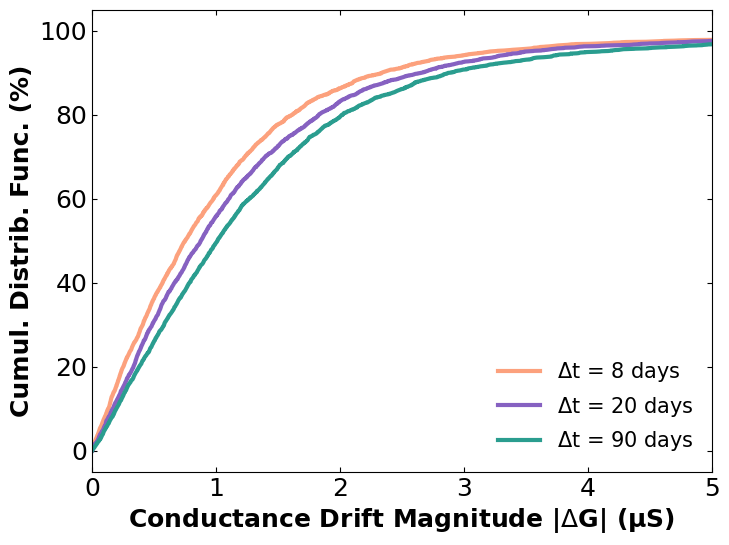

In [2]:
diffs_8d = np.abs(CONDUCTANCES_0d - CONDUCTANCES_8d) * 1e6
diffs_20d = np.abs(CONDUCTANCES_0d - CONDUCTANCES_20d) * 1e6
diffs_90d = np.abs(CONDUCTANCES_0d - CONDUCTANCES_90d) * 1e6

diffs_cdf_8d = np.sort(diffs_8d)
diffs_cdf_20d = np.sort(diffs_20d)
diffs_cdf_90d = np.sort(diffs_90d)
ys = np.linspace(0, 100, len(diffs_cdf_8d))

plt.figure(figsize=[8, 4.8* 8/6.4])
plt.plot(diffs_cdf_8d, ys, label="$\Delta$t = 8 days")
plt.plot(diffs_cdf_20d, ys, label="$\Delta$t = 20 days")
plt.plot(diffs_cdf_90d, ys, label="$\Delta$t = 90 days")
plt.xlim(0, 5)
plt.xlabel("Conductance Drift Magnitude |$\Delta$G| (µS)", fontdict={"weight": "bold"})
plt.ylabel("Cumul. Distrib. Func. (%)", fontdict={"weight": "bold"})
plt.legend()

plt.savefig("plots_out/e_retention_drift_conductance.svg", dpi=300, bbox_inches="tight")

In [5]:
np.count_nonzero(diffs_90d < 3)/diffs_90d.size

0.9071180555555556

---
## Accuracy vs Time

In [6]:
def date_to_hours(date, base_date):
    date = datetime.strptime(f"{date:04};1984", "%d%m;%Y")
    base_date = datetime.strptime(f"{base_date:04};1984", "%d%m;%Y")
    return int((date - base_date).total_seconds() / 3600)

df_mlp = pd.read_csv(RETENTION_FOLDER / "metrics.csv")
df_mlp = df_mlp[df_mlp["epoch"] >= 30][["epoch", "train_acc", "test_acc", "val_acc"]]
df_mlp[["train_acc", "test_acc", "val_acc"]] *= 100
df_mlp["epoch"] = df_mlp["epoch"].map(lambda x: date_to_hours(x, 2905)//24 if x > 30 else 0)
df_mlp.rename(columns={"epoch": "dt"}, inplace=True)
# df_mlp = df_mlp.groupby("dt").mean()

df_cf = pd.read_csv("data/run_logs/finals/animalsv3_32-48-48_2306_012202/metrics.csv")
df_cf = df_cf[df_cf["epoch"] >= 30][["epoch", "train_acc", "test_acc", "val_acc"]]
df_cf[["train_acc", "test_acc", "val_acc"]] *= 100
df_cf["epoch"] = df_cf["epoch"].map(lambda x: date_to_hours(x, 2306)//24 if x > 30 else 0)
df_cf.rename(columns={"epoch": "dt"}, inplace=True)
# df_cf = df_cf.groupby("dt").mean()

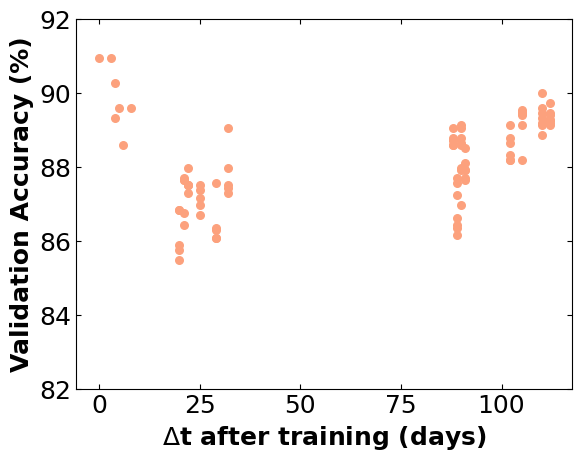

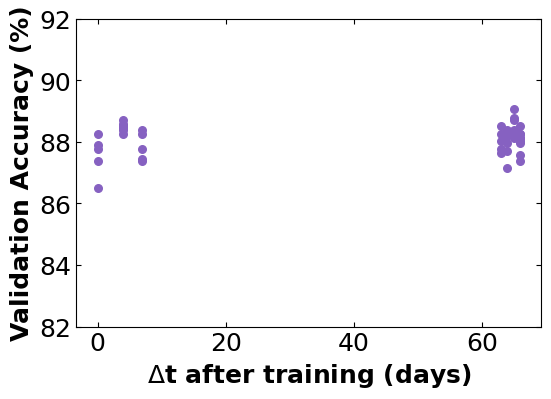

In [8]:
fig, ax = plt.subplots()
df_mlp.plot.scatter(x="dt", y="test_acc", ax=ax, s=30)
# ax.set_xscale("log")
ax.set_ylim(82, 92)
ax.set_xlabel("$\Delta$t after training (days)", fontdict={"weight": "bold"})
ax.set_ylabel("Validation Accuracy (%)", fontdict={"weight": "bold"})

plt.savefig("plots_out/d_retention_acc_mlp.svg", dpi=300, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(6,4))
df_cf.plot.scatter(x="dt", y="test_acc", ax=ax, c="C1", s=30)
# ax.set_xscale("log")
ax.set_ylim(82, 92)
ax.set_xlabel("$\Delta$t after training (days)", fontdict={"weight": "bold"})
ax.set_ylabel("Validation Accuracy (%)", fontdict={"weight": "bold"})

plt.savefig("plots_out/d_retention_acc_cf.svg", dpi=300, bbox_inches="tight")

---
## Understanding the drop between Δ=200h and Δ=500h 

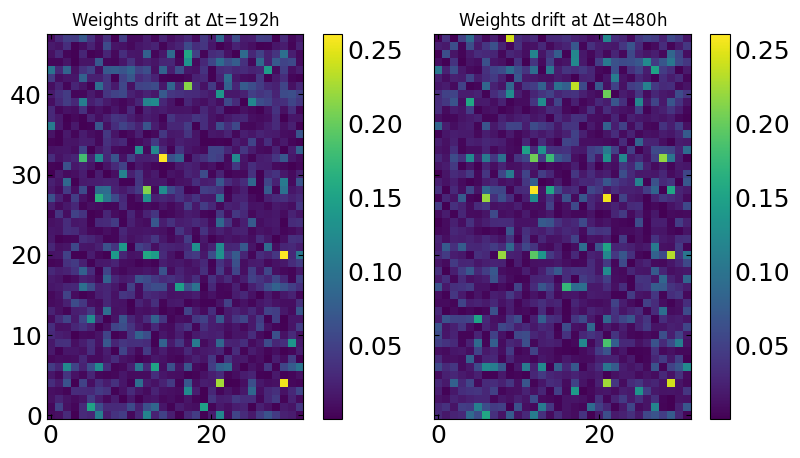

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10,5),sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.0)
im0 = axs[0].imshow(np.abs(PARAMS_0d[0] - PARAMS_8d[0]), origin="lower", vmax=0.26)
fig.colorbar(im0)
axs[0].set_title("Weights drift at $\Delta$t=192h", fontsize=12)

im1 = axs[1].imshow(np.abs(PARAMS_0d[0] - PARAMS_20d[0]), origin="lower", vmax=0.26)
fig.colorbar(im1)
axs[1].set_title("Weights drift at $\Delta$t=480h", fontsize=12);

Very small difference, what's happening?

### Which examples become missclassfied?

In [7]:
def compute_accuracy(model, dataloader):
    correct = total = 0
    all_corrects = []
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader, total=len(dataloader)):
            outputs = model(inputs)

            predicted = torch.max(outputs, 1).indices
            corrects = predicted == labels
            correct += corrects.sum().item()
            all_corrects.extend(corrects.detach().numpy())
            total += labels.size(0)

    return correct / total, np.array(all_corrects)

tsne = TSNE(n_components=2, perplexity=35, learning_rate = 200, max_iter=1000)
test_feats, test_labels = [], []

for feats, labels in TEST_LOADER:
    test_feats.extend(feats.detach().numpy())
    test_labels.extend(labels.detach().numpy())

test_feats = np.stack(test_feats, axis=0)
test_labels = np.stack(test_labels, axis=0)

tsne_embed = tsne.fit_transform(test_feats)

In [8]:
acc_0d, corrects_0d = compute_accuracy(MODEL_0d, TEST_LOADER)
acc_8d, corrects_8d = compute_accuracy(MODEL_8d, TEST_LOADER)
acc_20d, corrects_20d = compute_accuracy(MODEL_20d, TEST_LOADER)

100%|██████████| 9/9 [00:00<00:00, 900.09it/s]


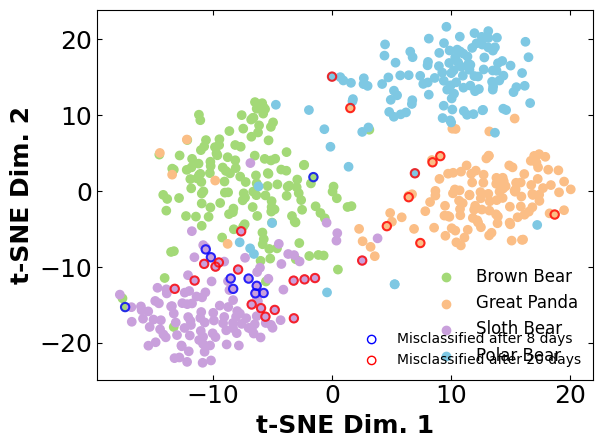

In [9]:
cmap = np.array(["#a3d977", "#fbbe86", "#c9a0dc", "#7ec8e3"])
plt.scatter(*tsne_embed.T, c=cmap[test_labels])
# plt.scatter(*(tsne_embed[~corrects_0d]).T, facecolor="None", edgecolor="green", linewidth=2, alpha=.8)
plt.scatter(*(tsne_embed[corrects_0d & ~corrects_8d]).T, facecolor="None", edgecolor="blue", linewidth=1.5, alpha=.8)
plt.scatter(*(tsne_embed[corrects_0d & corrects_8d & ~corrects_20d]).T, facecolor="None", edgecolor="red", linewidth=1.5, alpha=.8)

classes_labels = []
classes_labels.append(plt.scatter(None, None, color=cmap[0], label="Brown Bear"))
classes_labels.append(plt.scatter(None, None, color=cmap[1], label="Great Panda"))
classes_labels.append(plt.scatter(None, None, color=cmap[2], label="Sloth Bear"))
classes_labels.append(plt.scatter(None, None, color=cmap[3], label="Polar Bear"))

correctness_labels = []
# correctness_labels.append(plt.scatter(None, None, facecolor="None", edgecolor="None", label="$\Delta$t = 0h | 192h | 480h"))
# correctness_labels.append(plt.scatter(None, None, facecolor="None", edgecolor="green", label="ko | - | -"))
correctness_labels.append(plt.scatter(None, None, facecolor="None", edgecolor="blue", label="Misclassified after 8 days"))
correctness_labels.append(plt.scatter(None, None, facecolor="None", edgecolor="red", label="Misclassified after 20 days"))

legend1 = plt.gca().legend(classes_labels, [x.get_label() for x in classes_labels], fontsize=12)
legend2 = plt.gca().legend(correctness_labels, [x.get_label() for x in correctness_labels], fontsize=10, loc="lower right")

plt.xlabel("t-SNE Dim. 1", fontdict={"weight": "bold"})
plt.ylabel("t-SNE Dim. 2", fontdict={"weight": "bold"})
plt.gca().add_artist(legend1)
# plt.savefig("plots_out/e_retention_misclassified.svg", dpi=300, bbox_inches="tight")